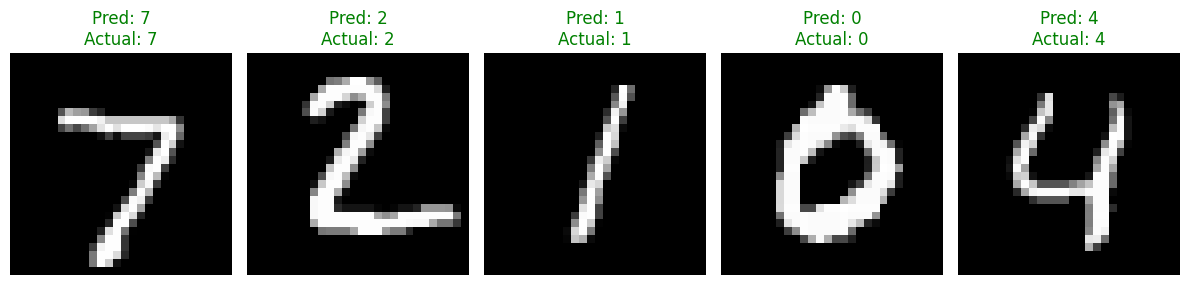

In [7]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_test_images = X_test

X_train = X_train.reshape(-1, 784).astype("float32") / 255.0
X_test = X_test.reshape(-1, 784).astype("float32") / 255.0

model = models.Sequential([
    layers.Input(shape=(784,)),
        layers.Dense(128, activation='relu'),
            layers.Dense(10, activation='softmax')
            ])
model.compile(
                optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                        metrics=['accuracy']
                        )
model.fit(X_train, y_train, epochs=5, batch_size=64, verbose=0)
predictions_probabilities = model.predict(X_test[:5], verbose=0)
predicted_labels = np.argmax(predictions_probabilities, axis=1)

plt.figure(figsize=(12, 3))
for i in range(5):
  plt.subplot(1, 5, i + 1)
  plt.imshow(X_test_images[i], cmap='gray')
  title_color = 'green' if predicted_labels[i] == y_test[i] else 'red'
  plt.title(f"Pred: {predicted_labels[i]}\nActual: {y_test[i]}", color=title_color)
  plt.axis('off')

plt.tight_layout()
plt.show()
